## Code for simulating theta cycling of place cells in a T-maze environment

In [1]:
import numpy as np
import brainpy.math as bm
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import cKDTree

import os
os.chdir("..")

from sweep.network_models import PCNet, PCParams
from sweep import plotting

from ratinabox.Environment import Environment
from ratinabox.Agent import Agent
from tqdm import tqdm

bm.set_dt(1.)

#auto reload
%load_ext autoreload
%autoreload 2

np.random.seed(10) #for reproducibility


In [3]:
def simulate_pcnet(net: PCNet, positions, theta_modulations):
    
    """Simulate DCNet over a trajectory of directions and velocity gains."""
    def step(i, position, theta_modulation):
        # update network
        net.step_run(i, position, theta_modulation)
        return net.center, net.r

    bump_center, bump_activity = bm.for_loop(step, (bm.arange(len(positions)), positions, theta_modulations), progress_bar=True)
    
    return bump_center.to_numpy(), bump_activity.to_numpy()


### 1. First let's simulate theta sweeps in a simple linear track environment

In [5]:
# 1. define the linear track and place cell density
L_track = 1.5   # length of the linear track (m)

# 2. Build the graph
graph = nx.Graph()
graph.graph = {"dx": 0.01, "type": "linear_track"} # dx is the spatial discretization (m), this is also the distance between two adjacent place cell fields
dx = graph.graph["dx"]

num_nodes = int(L_track / dx) + 1   # number of nodes, i.e., number of place cells

for i in range(num_nodes - 1):
    graph.add_edge(i, i + 1, weight=dx)


# mapping node to 2D position (this should match the environment layout we set in Ratinabox)
pos = {i: (i * dx, 0) for i in range(num_nodes)}

#### let's generate a narrow linear track environment with ratinabox and using the x dimenion only or we can just use a 1D environment. but this 2D one is more fun, isn't it?

/home/zilong/anaconda3/envs/anticipative_track_gpu/lib/python3.9/site-packages/ratinabox/utils.py:891: UserWarning: Found 1 unexpected params key(s) while initializing Agent object: 'rotation_velocity_std'.
If you intended to set this parameter, ignore this message. To see all default parameters for this class call Agent.get_all_default_params().
  warnings.warn(
  0%|          | 0/5000 [00:00<?, ?it/s]

100%|██████████| 5000/5000 [00:02<00:00, 2420.92it/s]
2025-10-09 17:48:59.051202: W external/xla/xla/service/gpu/nvptx_compiler.cc:763] The NVIDIA driver's CUDA version is 12.2 which is older than the ptxas CUDA version (12.5.40). Because the driver is older than the ptxas version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward compatibility packages.


    • To AUTOMATICALLY save all plots (recommended), set  `ratinabox.autosave_plots = True`
    • To MANUALLY save plots, call                        `ratinabox.utils.save_figure(figure_object, save_title).
      This warning will not be shown again
HINT: You can stylize plots to make them look like repo/paper by calling `ratinabox.stylize_plots()`
      This hint will not be shown again


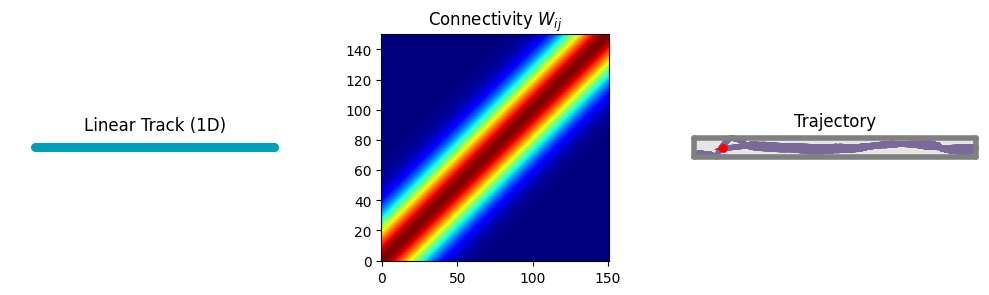

In [6]:
simulate_time = 5 #seconds

Env = Environment(params={
    'boundary':[[0,0],[0,0.1],[L_track,0.1],[L_track,0]],
    })
Ag = Agent(Env,params={'dt':0.001, 'speed_mean':0.5, 'speed_std':0.0, 'speed_coherence_time':0.08,
                      'rotation_velocity_std':180*np.pi/180, 'rotational_velocity_coherence_time':0.01})
Ag.pos = np.array([0.01,0.01]) #set initial position, need to be slightly offset of the boundary
for i in tqdm(range(int( simulate_time / Ag.dt))): 
    Ag.update()
    
position_xy = np.array(Ag.history["pos"])
velocity_xy = np.array(Ag.history["vel"])
timestamps = np.array(Ag.history["t"])

# embed the animal's position into the graph nodes
nodes = list(graph.nodes)
pos_bins = np.array([pos[n] for n in nodes]) 
# Build a KD-tree for fast nearest-neighbour search
tree = cKDTree(pos_bins)
# Query the nearest node for each time point in the trajectory
_, animal_pos_node_index = tree.query(position_xy, k=1)

fig, axs = plt.subplots(1,3,figsize=(10,3),dpi=100)
#plot the graph
nx.draw(graph, pos, node_size=30, ax=axs[0], node_color='#009FB9')
axs[0].set_aspect('equal', 'box')
axs[0].set_title("Linear Track (1D)")

# visualize the connectivity
synaptic_connection  = PCNet(graph, params=PCParams()).conn_mat
im = axs[1].imshow(synaptic_connection, cmap='jet', origin='lower')
axs[1].set_title("Connectivity $W_{ij}$")

#plot the trajectory
Ag.plot_trajectory(fig=fig, ax=axs[2], framerate=1000)
axs[2].set_title("Trajectory")

plt.tight_layout()


  0%|          | 0/5000 [00:00<?, ?it/s]

/tmp/ipykernel_3233831/2500740957.py:52: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


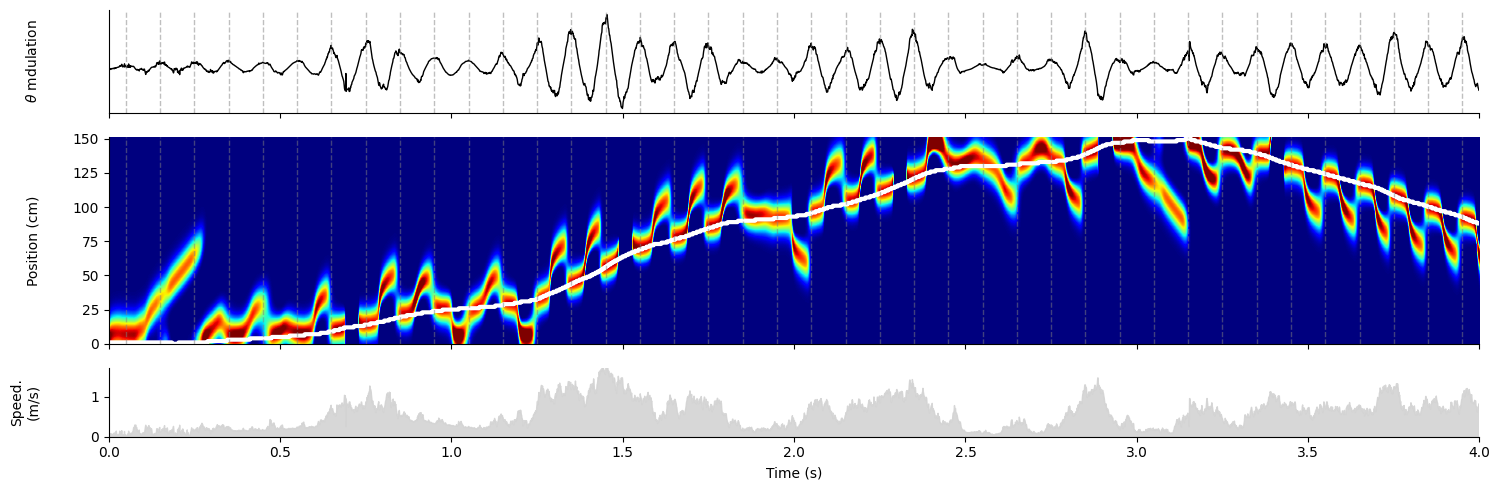

In [15]:
# build the network
params = PCParams(adaptation_strength=10, a=0.1)
pc_net = PCNet(graph, params=params)   

theta_cycle_len = 0.1 #seconds, theta cycle length, i.e., 100 ms
theta_strength = 10 #theta modulation strength

#get theta modulation strength which depends on speed, higher speed, higher modulationxs
speed = np.sqrt(velocity_xy[:,0]**2 + velocity_xy[:,1]**2)
speed_gains = np.abs(speed)/np.percentile(np.abs(speed), 99)
#compute theta modulation
cycle_fraction = (timestamps / theta_cycle_len) % 1
theta_phase = 2 * bm.pi * cycle_fraction - bm.pi
theta_modulations = 1 + theta_strength * bm.asarray(speed_gains) * bm.cos(theta_phase)

# simulate the DC network
internal_position, net_activity = simulate_pcnet(pc_net, animal_pos_node_index, theta_modulations)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 5),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={"height_ratios": [1.5, 3, 1]},
    dpi=100,
)

ax = axes[0]
#set theta_modulation outliear as median
theta_modulations = np.where(np.abs(theta_modulations - np.nanmedian(theta_modulations)) > 10 * np.nanstd(theta_modulations), np.nan, theta_modulations)
ax = plotting.plot_theta_modulation(ax, timestamps, theta_phase, theta_modulations, add_lines=True, atol=5e-2)

ax = axes[1]
ax = plotting.plot_population_activity_linear(ax, timestamps, theta_phase, net_activity, animal_pos_node_index, add_lines=True, atol=5e-2)

ax = axes[2]
ax = plotting.plot_linear_speed(ax, timestamps, speed)


for ax in axes:
    sns.despine(ax=ax)
    #align ylabels vertically
    ax.yaxis.set_label_coords(-0.05, 0.5)  # Shift labels left (adjust as needed)
    #labelsize as 14
    ax.tick_params(axis='both', which='major', labelsize=10)
    #labelsize as 14
    ax.yaxis.label.set_size(10)
    ax.xaxis.label.set_size(10)
    ax.set_xlim(0,4)

plt.tight_layout()


### 2. Let's simulate the T-maze environment

In [6]:
# 1. define the T-maze and place cell density
L_CJ = 1.5   # center arm length (m)
L_JL = 1.0   # left arm length (m)
L_JR = 1.0   # right arm length (m)  

# 2. define and build the graph
graph = nx.Graph()
graph.graph = {"dx": 0.01, "type": "linear_track"} # dx is the spatial discretization (m), this is also the distance between two adjacent place cell fields
dx = graph.graph['dx']

nC = int(L_CJ / dx)
nL = int(L_JL / dx)
nR = int(L_JR / dx)

# define the edge on central arm
for i in range(nC - 1):
    graph.add_edge(('C', i), ('C', i + 1), weight=dx)
# add the edge to junction J
graph.add_edge(('C', nC - 1), 'J', weight=dx)

# define the edge on left arm
for i in range(nL - 1):
    graph.add_edge(('L', i), ('L', i + 1), weight=dx)
# add the edge to junction J
graph.add_edge('J', ('L', 0), weight=dx)

#define the edge on right arm
for i in range(nR - 1):
    graph.add_edge(('R', i), ('R', i + 1), weight=dx)
#add the edge to junction J
graph.add_edge('J', ('R', 0), weight=dx)

nodes = list(graph.nodes)
N = len(nodes)
print(f"total number of nodes: {N}")
print(f"total numbe of edges: {len(graph.edges)}")


# # mapping node to 2D position (this should match the environment layout we set in Ratinabox)
pos = {}
for i in range(nC):
    pos[('C', i)] = (0, i * dx)
pos['J'] = (0, L_CJ)
for i in range(nL):
    pos[('L', i)] = (- (i + 1) * dx, L_CJ)
for i in range(nR):
    pos[('R', i)] = ((i + 1) * dx, L_CJ)



total number of nodes: 351
total numbe of edges: 350


/home/zilong/anaconda3/envs/anticipative_track_gpu/lib/python3.9/site-packages/ratinabox/utils.py:891: UserWarning: Found 1 unexpected params key(s) while initializing Agent object: 'rotation_velocity_std'.
If you intended to set this parameter, ignore this message. To see all default parameters for this class call Agent.get_all_default_params().
  warnings.warn(
  0%|          | 0/8000 [00:00<?, ?it/s]

100%|██████████| 8000/8000 [00:03<00:00, 2279.50it/s]


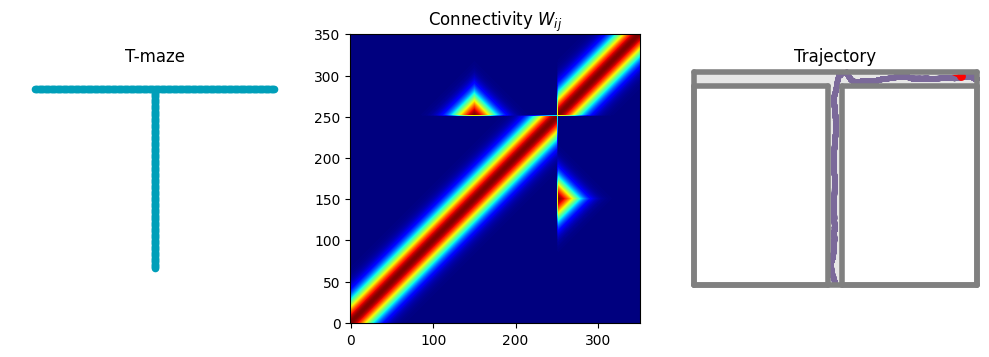

In [7]:
np.random.seed(123)  # for reproducibility

simulate_time = 8 #seconds

TMaze_Env = Environment(params={
    'boundary':[[-1,0],[-1,1.5],[1.0,1.5],[1.0,0]],
    'holes' : [[[-0.05,0],[-0.05,1.4],[-1.0,1.4],[-1.0,0.]],
               [[0.05,0.],[0.05,1.4],[1.0,1.4],[1.0,0.]]],
    })
#dt is 1 ms

Ag = Agent(TMaze_Env,params={'dt':0.001, 'speed_mean':0.3, 'speed_std':0.1, 'speed_coherence_time':0.08,
                      'rotation_velocity_std':180*np.pi/180, 'rotational_velocity_coherence_time':0.01})

Ag.pos = np.array([0,0.01]) #starting position, need to be slightly offset of the boundary
for i in tqdm(range(int(simulate_time / Ag.dt))): 
    Ag.update() #let the agent move freely

position_xy = np.array(Ag.history["pos"])
velocity_xy = np.array(Ag.history["vel"])
timestamps = np.array(Ag.history["t"])
    
pos_bins = np.array([pos[n] for n in nodes]) 
# Build a KD-tree for fast nearest-neighbour search
tree = cKDTree(pos_bins)
# Query the nearest node for each time point in the trajectory
_, animal_pos_node_index = tree.query(position_xy, k=1)


fig, axs = plt.subplots(1, 3, figsize=(10, 4))

#plot the graph
nx.draw(graph, pos, node_size=20, ax=axs[0], node_color='#009FB9')
axs[0].set_aspect('equal', 'box')
axs[0].set_title("T-maze")

#visualize the connectivity
synaptic_connection  = PCNet(graph, params=PCParams()).conn_mat
im = axs[1].imshow(synaptic_connection, cmap='jet', origin='lower')
axs[1].set_title("Connectivity $W_{ij}$")
    
Ag.plot_trajectory(fig=fig, framerate=1000, ax=axs[2])
axs[2].set_title("Trajectory")

plt.tight_layout()


### Build the network, simulate and visualize the results

  0%|          | 0/8000 [00:00<?, ?it/s]

/tmp/ipykernel_3230880/852853124.py:56: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


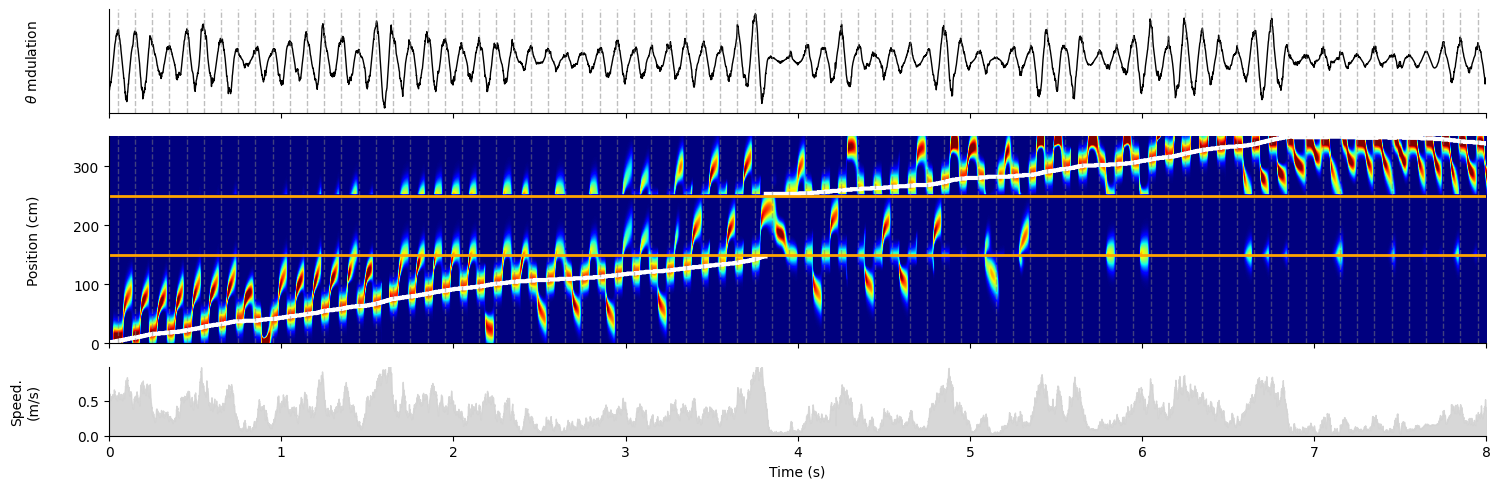

In [18]:
# build the network
params = PCParams(adaptation_strength=15, a=0.2)
pc_net = PCNet(graph, params=params)   

theta_cycle_len = 0.1 #seconds, theta cycle length, i.e., 100 ms
theta_strength = 10 #theta modulation strength

#get theta modulation strength which depends on speed, higher speed, higher modulationxs
speed = np.sqrt(velocity_xy[:,0]**2 + velocity_xy[:,1]**2)
speed_gains = np.abs(speed)/np.percentile(np.abs(speed), 99)
#compute theta modulation
cycle_fraction = (timestamps / theta_cycle_len) % 1
theta_phase = 2 * bm.pi * cycle_fraction - bm.pi
theta_modulations = 1 + theta_strength * bm.asarray(speed_gains) * bm.cos(theta_phase)

# simulate the DC network
internal_position, net_activity = simulate_pcnet(pc_net, animal_pos_node_index, theta_modulations)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 5),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={"height_ratios": [1.5, 3, 1]},
    dpi=100,
)

ax = axes[0]
#set theta_modulation outliear as median
theta_modulations = np.where(np.abs(theta_modulations - np.nanmedian(theta_modulations)) > 10 * np.nanstd(theta_modulations), np.nan, theta_modulations)
ax = plotting.plot_theta_modulation(ax, timestamps, theta_phase, theta_modulations, add_lines=True, atol=5e-2)

ax = axes[1]
ax = plotting.plot_population_activity_linear(ax, timestamps, theta_phase, net_activity, animal_pos_node_index, add_lines=True, atol=5e-2)
#add y=nc, y=nc+nL lines to split the arms
ax.axhline(nC, color='orange', linestyle='-', linewidth=2)
ax.axhline(nC+nL, color='orange', linestyle='-', linewidth=2)


ax = axes[2]
ax = plotting.plot_linear_speed(ax, timestamps, speed)


for ax in axes:
    sns.despine(ax=ax)
    #align ylabels vertically
    ax.yaxis.set_label_coords(-0.05, 0.5)  # Shift labels left (adjust as needed)
    #labelsize as 14
    ax.tick_params(axis='both', which='major', labelsize=10)
    #labelsize as 14
    ax.yaxis.label.set_size(10)
    ax.xaxis.label.set_size(10)
    ax.set_xlim(0,simulate_time)

plt.tight_layout()


## 3, Let's simulate a multi-arm maze environment, say four arm maze

In [19]:
# 1. Define maze geometry
L_CJ = 1.0   # central stem length (m)
L_ARM = 0.5  # branch arm length (m)

# 2. Initialise graph
graph = nx.Graph()
graph.graph = {"dx": 0.01, "type": "four_arm_maze"}
dx = graph.graph['dx']

nC = int(L_CJ / dx)
nA = int(L_ARM / dx)

# 3. Build central (vertical) stem
for i in range(nC - 1):
    graph.add_edge(('C', i), ('C', i + 1), weight=dx)

# Junction node
graph.add_edge(('C', nC - 1), 'J', weight=dx)

# 4. Define four arms around the junction J
arms = ['LU', 'LD', 'RU', 'RD']  # left-up, left-down, right-up, right-down

for arm in arms:
    for i in range(nA - 1):
        graph.add_edge((arm, i), (arm, i + 1), weight=dx)
    # connect each arm’s first node to junction J
    graph.add_edge('J', (arm, 0), weight=dx)

# 5. Summary
nodes = list(graph.nodes)
print(f"Total number of nodes: {len(nodes)}")
print(f"Total number of edges: {len(graph.edges)}")

# mapping node to 2D position (this should match the environment layout we set in Ratinabox)
pos = {}

# central stem: vertical from (0,0) to (0,L_CJ)
for i in range(nC):
    pos[('C', i)] = (0, i * dx)

# junction
pos['J'] = (0, L_CJ)

# diagonal step size so that true length = L_ARM
step = dx / np.sqrt(2)

# left-up arm
for i in range(nA):
    pos[('LU', i)] = (-i * step, L_CJ + i * step)

# left-down arm
for i in range(nA):
    pos[('LD', i)] = (-i * step, L_CJ - i * step)

# right-up arm
for i in range(nA):
    pos[('RU', i)] = (i * step, L_CJ + i * step)

# right-down arm
for i in range(nA):
    pos[('RD', i)] = (i * step, L_CJ - i * step)



Total number of nodes: 301
Total number of edges: 300


/home/zilong/anaconda3/envs/anticipative_track_gpu/lib/python3.9/site-packages/ratinabox/utils.py:891: UserWarning: Found 1 unexpected params key(s) while initializing Agent object: 'rotation_velocity_std'.
If you intended to set this parameter, ignore this message. To see all default parameters for this class call Agent.get_all_default_params().
  warnings.warn(
  0%|          | 0/8000 [00:00<?, ?it/s]

100%|██████████| 8000/8000 [00:03<00:00, 2169.46it/s]


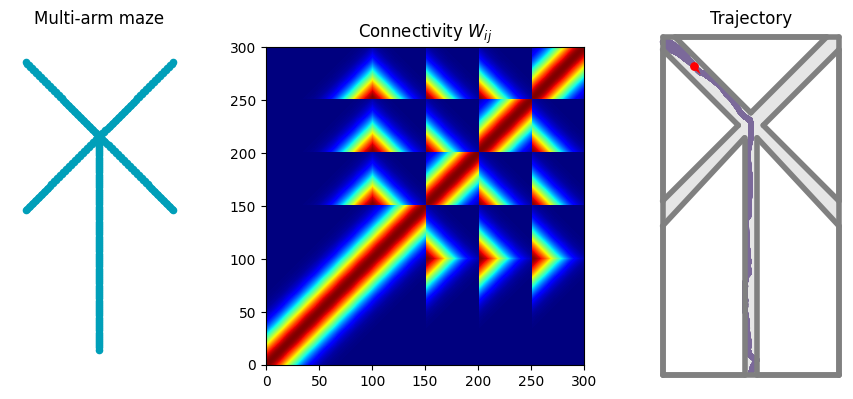

In [20]:
np.random.seed(1)  # for reproducibility

simulate_time = 8 #seconds

# 1. Define the four-arm maze geometry (a central cross)
# Each arm extends diagonally from a central junction at (0, 0.75)
FourArmMaze_Env = Environment(params={
    # Outer boundary (approximate cross shape)
    'boundary': [
        [-np.sqrt(2)/4, 0], [-np.sqrt(2)/4, 1.0+np.sqrt(2)/4],
        [np.sqrt(2)/4, 1.0+np.sqrt(2)/4], [np.sqrt(2)/4, 0],
    ],

    # Cut-out 'holes' to create four arms around a junction
    # Central stem roughly along y-axis, arms extend diagonally
    'holes': [
        #hole 1
        [[-np.sqrt(2)/4, 0], [-np.sqrt(2)/4, 1.0-np.sqrt(2)/4-0.05], [-0.025, 1.0-0.05], [-0.025, 0.]],
        #hole 2
        [[-np.sqrt(2)/4, 1.0-np.sqrt(2)/4+0.05], [-np.sqrt(2)/4, 1.0+np.sqrt(2)/4-0.05], [-0.05, 1.0], [-0.05, 1.0]],
        #hole 3
        [[np.sqrt(2)/4, 0], [np.sqrt(2)/4, 1.0-np.sqrt(2)/4-0.05], [0.025, 1.0-0.05], [0.025, 0.]],
        #hole 4
        [[np.sqrt(2)/4, 1.0-np.sqrt(2)/4+0.05], [np.sqrt(2)/4, 1.0+np.sqrt(2)/4-0.05], [0.05, 1.0], [0.05, 1.0]],
        #hole 5
        [[0, 1.0+0.05], [-np.sqrt(2)/4+0.05, 1.0+np.sqrt(2)/4], [np.sqrt(2)/4-0.05, 1.0+np.sqrt(2)/4], [0, 1.0+0.05]],
    ],
})

# 2. Define the agent
Ag = Agent(
    FourArmMaze_Env,
    params={
        'dt': 0.001,
        'speed_mean': 0.2,
        'speed_std': 0.1,
        'speed_coherence_time': 0.08,
        'rotation_velocity_std': 180 * np.pi / 180,
        'rotational_velocity_coherence_time': 0.01,
    }
)

# 3. Set initial position slightly inside central corridor
Ag.pos = np.array([0.0, 0.01])

# 4. Simulate agent’s motion
for _ in tqdm(range(int(simulate_time / Ag.dt))):
    Ag.update()

position_xy = np.array(Ag.history["pos"])
velocity_xy = np.array(Ag.history["vel"])
timestamps = np.array(Ag.history["t"])

pos_bins = np.array([pos[n] for n in nodes]) 
# Build a KD-tree for fast nearest-neighbour search
tree = cKDTree(pos_bins)
# Query the nearest node for each time point in the trajectory
_, animal_pos_node_index = tree.query(position_xy, k=1)


fig, axs = plt.subplots(1, 3, figsize=(10, 4))

#plot the graph
nx.draw(graph, pos, node_size=20, ax=axs[0], node_color='#009FB9')
axs[0].set_aspect('equal', 'box')
axs[0].set_title("Multi-arm maze")

#visualize the connectivity
synaptic_connection  = PCNet(graph, params=PCParams()).conn_mat
im = axs[1].imshow(synaptic_connection, cmap='jet', origin='lower')
axs[1].set_title("Connectivity $W_{ij}$")
    
Ag.plot_trajectory(fig=fig, framerate=1000, ax=axs[2])
axs[2].set_title("Trajectory")

plt.tight_layout()


  0%|          | 0/8000 [00:00<?, ?it/s]

/tmp/ipykernel_3230880/1918677462.py:58: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


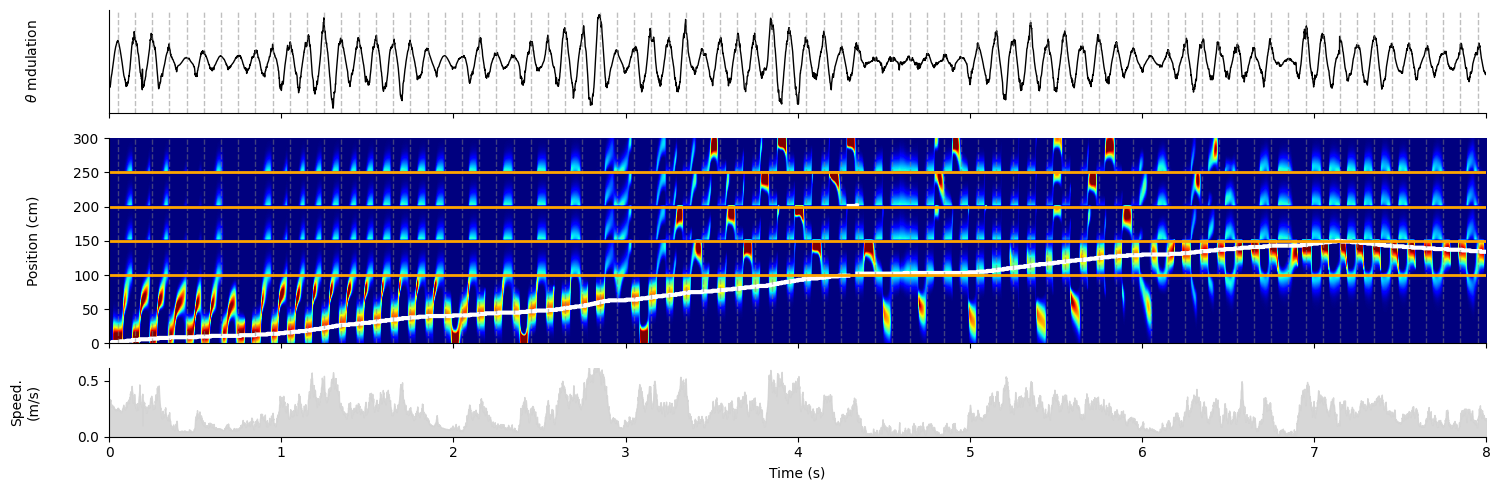

In [25]:
# build the network
params = PCParams(adaptation_strength=20, a=0.2)
pc_net = PCNet(graph, params=params)   

theta_cycle_len = 0.1 #seconds, theta cycle length, i.e., 100 ms
theta_strength = 10 #theta modulation strength

#get theta modulation strength which depends on speed, higher speed, higher modulationxs
speed = np.sqrt(velocity_xy[:,0]**2 + velocity_xy[:,1]**2)
speed_gains = np.abs(speed)/np.percentile(np.abs(speed), 99)
#compute theta modulation
cycle_fraction = (timestamps / theta_cycle_len) % 1
theta_phase = 2 * bm.pi * cycle_fraction - bm.pi
theta_modulations = 1 + theta_strength * bm.asarray(speed_gains) * bm.cos(theta_phase)

# simulate the DC network
internal_position, net_activity = simulate_pcnet(pc_net, animal_pos_node_index, theta_modulations)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 5),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={"height_ratios": [1.5, 3, 1]},
    dpi=100,
)

ax = axes[0]
#set theta_modulation outliear as median
theta_modulations = np.where(np.abs(theta_modulations - np.nanmedian(theta_modulations)) > 10 * np.nanstd(theta_modulations), np.nan, theta_modulations)
ax = plotting.plot_theta_modulation(ax, timestamps, theta_phase, theta_modulations, add_lines=True, atol=5e-2)

ax = axes[1]
ax = plotting.plot_population_activity_linear(ax, timestamps, theta_phase, net_activity, animal_pos_node_index, add_lines=True, atol=5e-2)
#add y=nc, y=nc+nL lines to split the arms
ax.axhline(nC, color='orange', linestyle='-', linewidth=2)
ax.axhline(nC+nA, color='orange', linestyle='-', linewidth=2)
ax.axhline(nC+2*nA, color='orange', linestyle='-', linewidth=2)
ax.axhline(nC+3*nA, color='orange', linestyle='-', linewidth=2)


ax = axes[2]
ax = plotting.plot_linear_speed(ax, timestamps, speed)


for ax in axes:
    sns.despine(ax=ax)
    #align ylabels vertically
    ax.yaxis.set_label_coords(-0.05, 0.5)  # Shift labels left (adjust as needed)
    #labelsize as 14
    ax.tick_params(axis='both', which='major', labelsize=10)
    #labelsize as 14
    ax.yaxis.label.set_size(10)
    ax.xaxis.label.set_size(10)
    ax.set_xlim(0,simulate_time)

plt.tight_layout()
